In [1]:
print("Sales Analytics Project Started!")
print("Python is ready.")

Sales Analytics Project Started!
Python is ready.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("All libraries imported successfully!")

Pandas version: 2.2.3
NumPy version: 2.1.3
All libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [7]:
print(pd.__version__)


2.2.3


In [9]:
import pandas as pd

file_path = "../data/Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


Dataset loaded successfully!
Dataset shape: (541909, 8)


In [10]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [12]:
df.columns.tolist()


['InvoiceNo',
 'StockCode',
 'Description',
 'Quantity',
 'InvoiceDate',
 'UnitPrice',
 'CustomerID',
 'Country']

In [13]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [14]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent.sort_values(ascending=False).round(2)

CustomerID     24.93
Description     0.27
StockCode       0.00
InvoiceNo       0.00
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
Country         0.00
dtype: float64

In [16]:
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 5268


In [17]:
sales_df = df.copy()

print("Original rows:", len(df))
print("Working-copy rows:", len(sales_df))
print("Duplicate rows:", sales_df.duplicated().sum())

Original rows: 541909
Working-copy rows: 541909
Duplicate rows: 5268


In [18]:
sales_df = sales_df.drop_duplicates()

print("Rows before cleaning:", len(df))
print("Rows after removing duplicates:", len(sales_df))
print("Duplicates remaining:", sales_df.duplicated().sum())

Rows before cleaning: 541909
Rows after removing duplicates: 536641
Duplicates remaining: 0


In [19]:
print("Zero quantities:", (sales_df["Quantity"] == 0).sum())
print("Negative quantities:", (sales_df["Quantity"] < 0).sum())
print("Zero unit prices:", (sales_df["UnitPrice"] == 0).sum())
print("Negative unit prices:", (sales_df["UnitPrice"] < 0).sum())

Zero quantities: 0
Negative quantities: 10587
Zero unit prices: 2510
Negative unit prices: 2


In [20]:
sales_df[sales_df["Quantity"] < 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [21]:
cancelled_invoices = sales_df[
    sales_df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Rows with C-prefixed invoices:", len(cancelled_invoices))
print("Unique C-prefixed invoices:", cancelled_invoices["InvoiceNo"].nunique())

Rows with C-prefixed invoices: 9251
Unique C-prefixed invoices: 3836


In [22]:
negative_qty = sales_df["Quantity"] < 0
c_invoice = sales_df["InvoiceNo"].astype(str).str.startswith("C")

print("Negative quantity rows:", negative_qty.sum())
print("Negative quantity rows with C invoice:", (negative_qty & c_invoice).sum())
print("Negative quantity rows without C invoice:", (negative_qty & ~c_invoice).sum())

Negative quantity rows: 10587
Negative quantity rows with C invoice: 9251
Negative quantity rows without C invoice: 1336


In [23]:
sales_df[
    (sales_df["Quantity"] < 0) &
    (~sales_df["InvoiceNo"].astype(str).str.startswith("C"))
].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [24]:
unusual_rows = sales_df[
    (sales_df["Quantity"] < 0) &
    (sales_df["UnitPrice"] == 0) &
    (sales_df["Description"].isna())
]

print("Unusual rows:", len(unusual_rows))

Unusual rows: 862


In [25]:
unusual_rows = sales_df[
    (sales_df["Quantity"] < 0) &
    (sales_df["UnitPrice"] == 0) &
    (sales_df["Description"].isna())
]

print("Unusual rows:", len(unusual_rows))

Unusual rows: 862


In [26]:
print("Missing Customer IDs:", unusual_rows["CustomerID"].isna().sum())
print("Unique invoice numbers:", unusual_rows["InvoiceNo"].nunique())

Missing Customer IDs: 862
Unique invoice numbers: 862


In [27]:
print("Total unique invoice numbers:", sales_df["InvoiceNo"].nunique())
print("Total rows in cleaned dataset:", len(sales_df))

Total unique invoice numbers: 25900
Total rows in cleaned dataset: 536641


In [28]:
unusual_percentage = (len(unusual_rows) / len(sales_df)) * 100

print("Unusual rows:", len(unusual_rows))
print("Percentage of dataset:", round(unusual_percentage, 2), "%")

Unusual rows: 862
Percentage of dataset: 0.16 %


In [29]:
analysis_df = sales_df[
    (sales_df["Quantity"] > 0) &
    (sales_df["UnitPrice"] > 0)
].copy()

print("Original cleaned rows:", len(sales_df))
print("Rows for positive-sales analysis:", len(analysis_df))
print("Rows excluded from this analysis:", len(sales_df) - len(analysis_df))

Original cleaned rows: 536641
Rows for positive-sales analysis: 524878
Rows excluded from this analysis: 11763


In [30]:
analysis_df["Revenue"] = (
    analysis_df["Quantity"] * analysis_df["UnitPrice"]
)

print("Revenue column created successfully!")
analysis_df[["Description", "Quantity", "UnitPrice", "Revenue"]].head(10)

Revenue column created successfully!


,Description,Quantity,UnitPrice,Revenue
0,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,WHITE METAL LANTERN,6,3.39,20.34
2,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34
5,SET 7 BABUSHKA NESTING BOXES,2,7.65,15.30
6,GLASS STAR FROSTED T-LIGHT HOLDER,6,4.25,25.50
7,HAND WARMER UNION JACK,6,1.85,11.10
8,HAND WARMER RED POLKA DOT,6,1.85,11.10
9,ASSORTED COLOUR BIRD ORNAMENT,32,1.69,54.08


In [31]:
total_revenue = analysis_df["Revenue"].sum()

print("Total Revenue: £", round(total_revenue, 2))

Total Revenue: £ 10642110.8


In [32]:
total_units_sold = analysis_df["Quantity"].sum()

print("Total Units Sold:", total_units_sold)

Total Units Sold: 5572420


In [33]:
total_orders = analysis_df["InvoiceNo"].nunique()

average_order_value = total_revenue / total_orders

print("Total Orders:", total_orders)
print("Average Order Value: £", round(average_order_value, 2))

Total Orders: 19960
Average Order Value: £ 533.17


In [34]:
total_customers = analysis_df["CustomerID"].nunique()

print("Total Unique Customers:", total_customers)

Total Unique Customers: 4338


In [35]:
country_revenue = (
    analysis_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_revenue

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

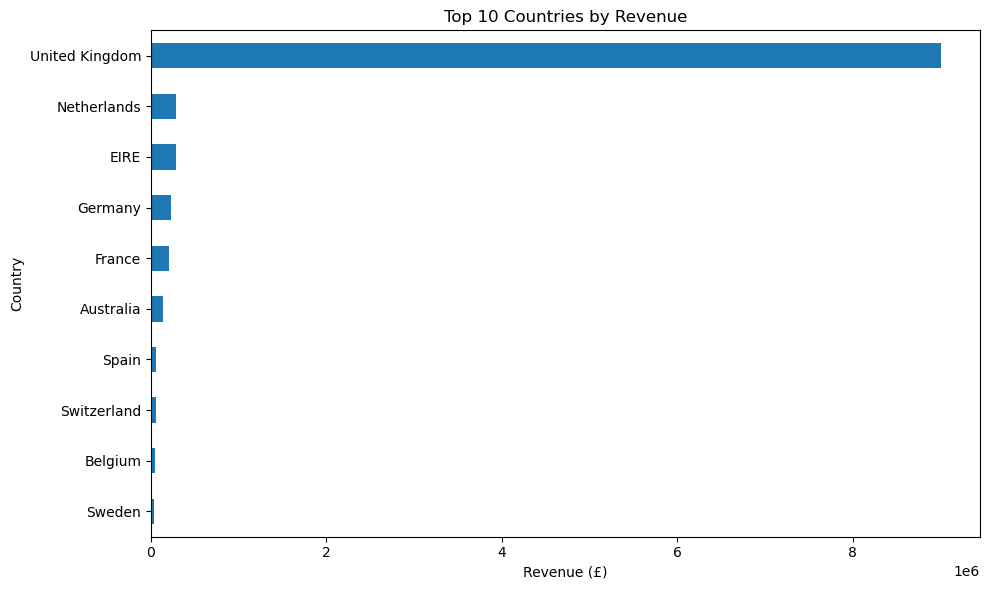

In [36]:
import matplotlib.pyplot as plt

country_revenue.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Countries by Revenue"
)

plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

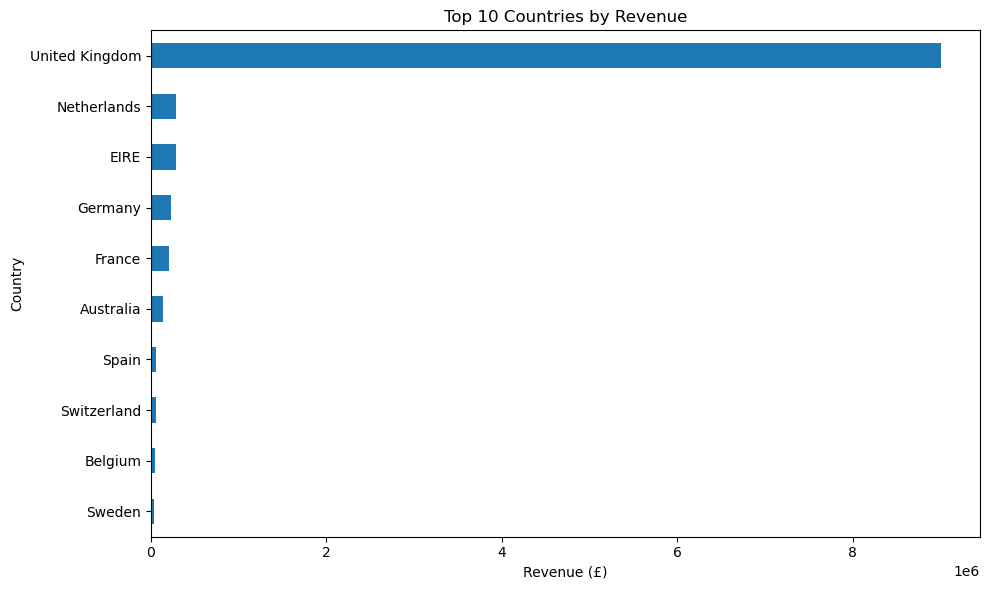

In [37]:
import matplotlib.pyplot as plt

country_revenue.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Countries by Revenue"
)

plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [39]:
analysis_df["InvoiceDate"] = pd.to_datetime(
    analysis_df["InvoiceDate"]
)

analysis_df["YearMonth"] = (
    analysis_df["InvoiceDate"].dt.to_period("M")
)

monthly_revenue = (
    analysis_df.groupby("YearMonth")["Revenue"]
    .sum()
)

print("Monthly revenue calculated successfully!")
monthly_revenue

Monthly revenue calculated successfully!


YearMonth
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64

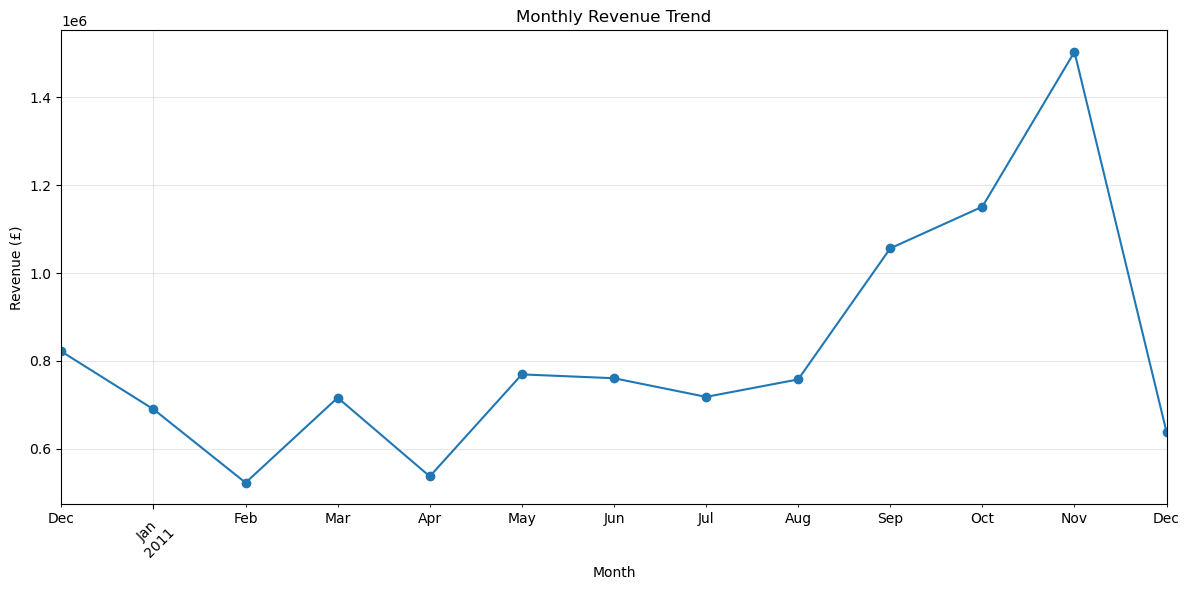

In [40]:
monthly_revenue.plot(
    kind="line",
    figsize=(12, 6),
    marker="o",
    title="Monthly Revenue Trend"
)

plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
best_month = monthly_revenue.idxmax()
best_revenue = monthly_revenue.max()

print("Highest Revenue Month:", best_month)
print("Highest Monthly Revenue: £", round(best_revenue, 2))

Highest Revenue Month: 2011-11
Highest Monthly Revenue: £ 1503866.78


In [42]:
lowest_month = monthly_revenue.idxmin()
lowest_revenue = monthly_revenue.min()

print("Lowest Revenue Month:", lowest_month)
print("Lowest Monthly Revenue: £", round(lowest_revenue, 2))

Lowest Revenue Month: 2011-02
Lowest Monthly Revenue: £ 522545.56


In [43]:
top_products = (
    analysis_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64

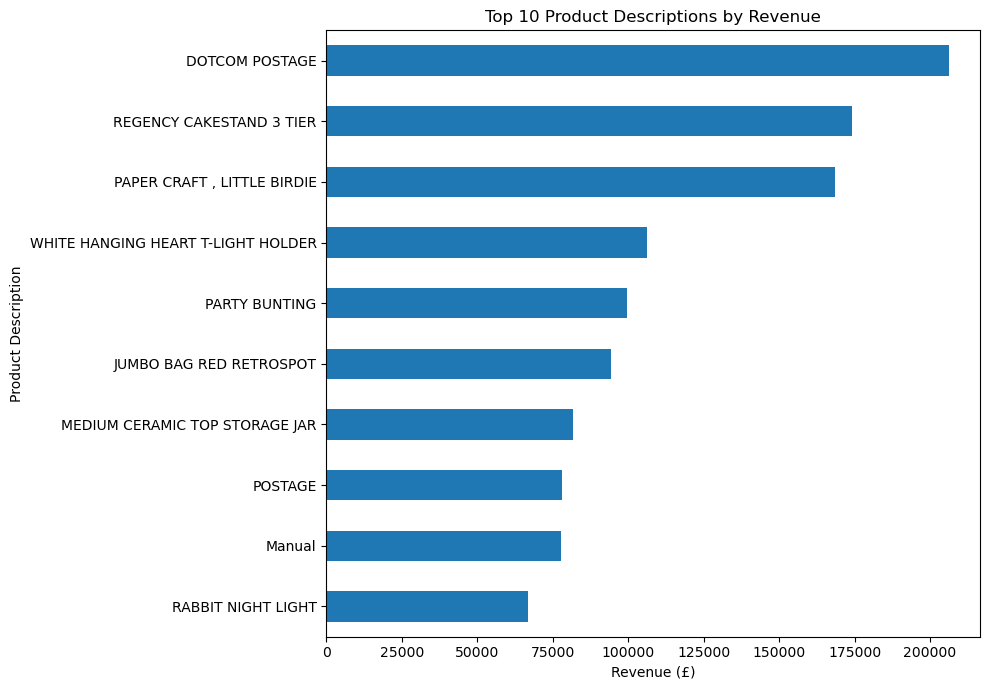

In [44]:
top_products.sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    title="Top 10 Product Descriptions by Revenue"
)

plt.xlabel("Revenue (£)")
plt.ylabel("Product Description")
plt.tight_layout()
plt.show()

In [45]:
analysis_df["Description"].value_counts().head(15)

Description
WHITE HANGING HEART T-LIGHT HOLDER    2311
JUMBO BAG RED RETROSPOT               2109
REGENCY CAKESTAND 3 TIER              2007
PARTY BUNTING                         1699
LUNCH BAG RED RETROSPOT               1581
ASSORTED COLOUR BIRD ORNAMENT         1476
SET OF 3 CAKE TINS PANTRY DESIGN      1392
PACK OF 72 RETROSPOT CAKE CASES       1352
LUNCH BAG  BLACK SKULL.               1301
NATURAL SLATE HEART CHALKBOARD        1255
JUMBO BAG PINK POLKADOT               1232
HEART OF WICKER SMALL                 1219
JUMBO STORAGE BAG SUKI                1194
PAPER CHAIN KIT 50'S CHRISTMAS        1184
JUMBO SHOPPER VINTAGE RED PAISLEY     1180
Name: count, dtype: int64

In [46]:
description = analysis_df["Description"].fillna("").str.upper()

merchandise_df = analysis_df[
    ~description.str.contains(r"POSTAGE|MANUAL", regex=True)
].copy()

merchandise_revenue = merchandise_df["Revenue"].sum()

print("Merchandise rows:", len(merchandise_df))
print("Merchandise revenue: £", round(merchandise_revenue, 2))

Merchandise rows: 522729
Merchandise revenue: £ 10280007.33


In [47]:
top_merchandise = (
    merchandise_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_merchandise

Description
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
Name: Revenue, dtype: float64

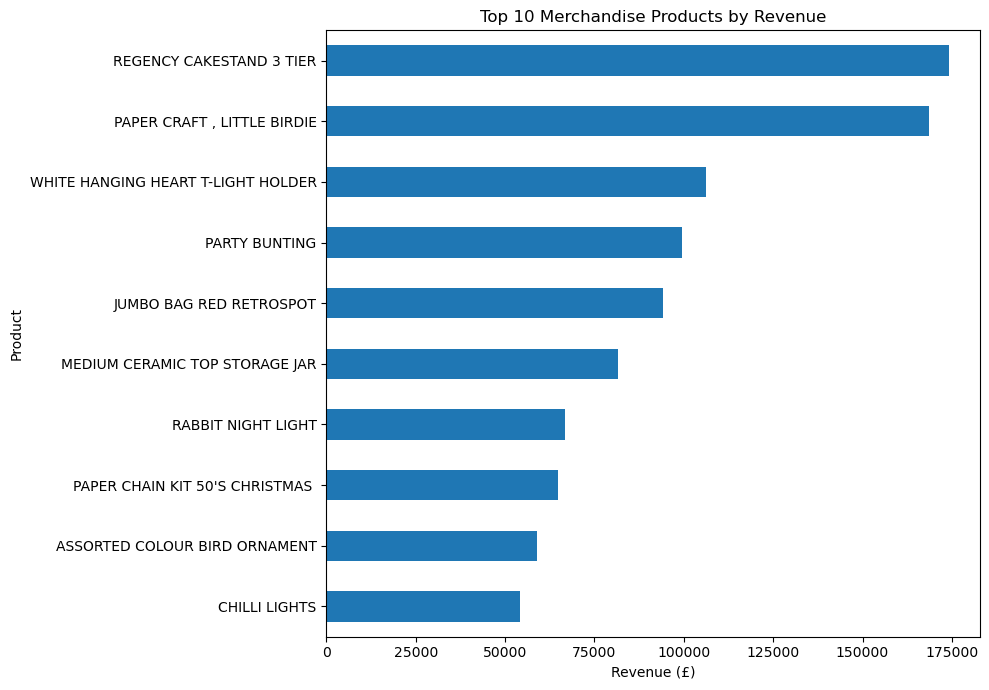

In [48]:
top_merchandise.sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    title="Top 10 Merchandise Products by Revenue"
)

plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [49]:
top_customers = (
    merchandise_df.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

CustomerID
14646.0    279138.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    140336.83
12415.0    124564.53
14156.0    117210.08
17511.0     91062.38
12346.0     77183.60
16029.0     72708.09
Name: Revenue, dtype: float64

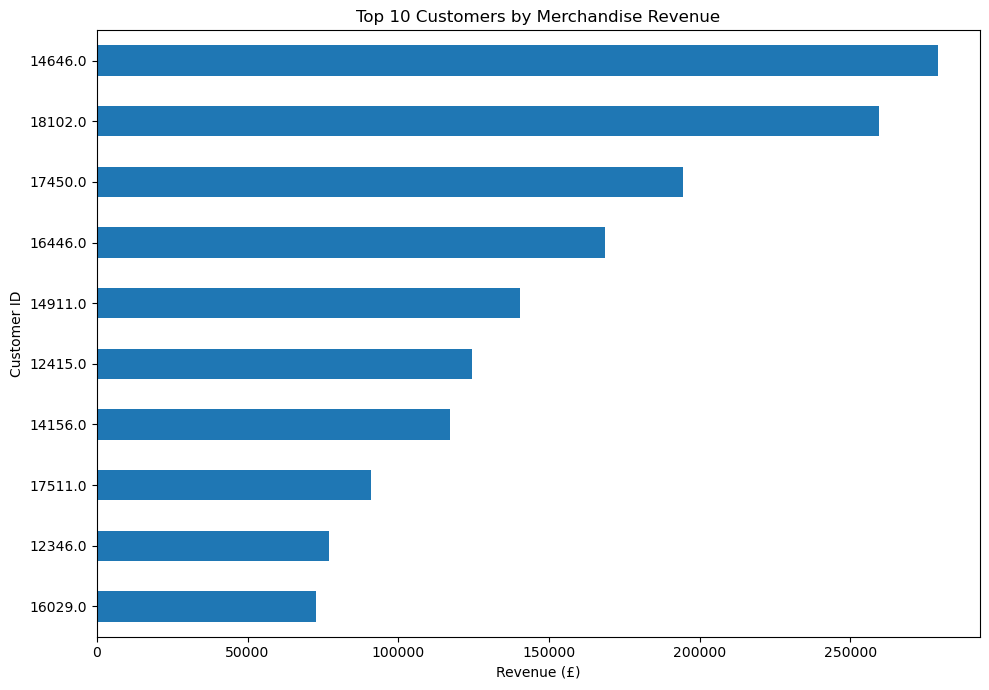

In [50]:
top_customers.sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    title="Top 10 Customers by Merchandise Revenue"
)

plt.xlabel("Revenue (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

In [51]:
customer_revenue = (
    merchandise_df.groupby("CustomerID")["Revenue"].sum()
)

average_revenue_per_customer = customer_revenue.mean()

print("Unique Customers:", customer_revenue.count())
print(
    "Average Revenue per Customer: £",
    round(average_revenue_per_customer, 2)
)

Unique Customers: 4335
Average Revenue per Customer: £ 2017.09


In [52]:
customer_orders = (
    merchandise_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

repeat_customers = customer_orders[customer_orders > 1]

print("Total identified customers:", customer_orders.count())
print("Repeat customers:", len(repeat_customers))
print(
    "Repeat customer percentage:",
    round(len(repeat_customers) / customer_orders.count() * 100, 2),
    "%"
)


Total identified customers: 4335
Repeat customers: 2830
Repeat customer percentage: 65.28 %


In [53]:
one_time_customers = customer_orders[customer_orders == 1]

print("One-time customers:", len(one_time_customers))
print(
    "One-time customer percentage:",
    round(len(one_time_customers) / customer_orders.count() * 100, 2),
    "%"
)

One-time customers: 1505
One-time customer percentage: 34.72 %


In [54]:
customer_revenue = (
    merchandise_df.groupby("CustomerID")["Revenue"].sum()
)

repeat_ids = customer_orders[customer_orders > 1].index
one_time_ids = customer_orders[customer_orders == 1].index

repeat_revenue = customer_revenue.reindex(repeat_ids).sum()
one_time_revenue = customer_revenue.reindex(one_time_ids).sum()

print("Repeat customer revenue: £", round(repeat_revenue, 2))
print("One-time customer revenue: £", round(one_time_revenue, 2))

Repeat customer revenue: £ 8116911.94
One-time customer revenue: £ 627166.7


In [55]:
repeat_avg_revenue = repeat_revenue / len(repeat_ids)
one_time_avg_revenue = one_time_revenue / len(one_time_ids)

print("Average revenue per repeat customer: £",
      round(repeat_avg_revenue, 2))

print("Average revenue per one-time customer: £",
      round(one_time_avg_revenue, 2))

Average revenue per repeat customer: £ 2868.17
Average revenue per one-time customer: £ 416.72


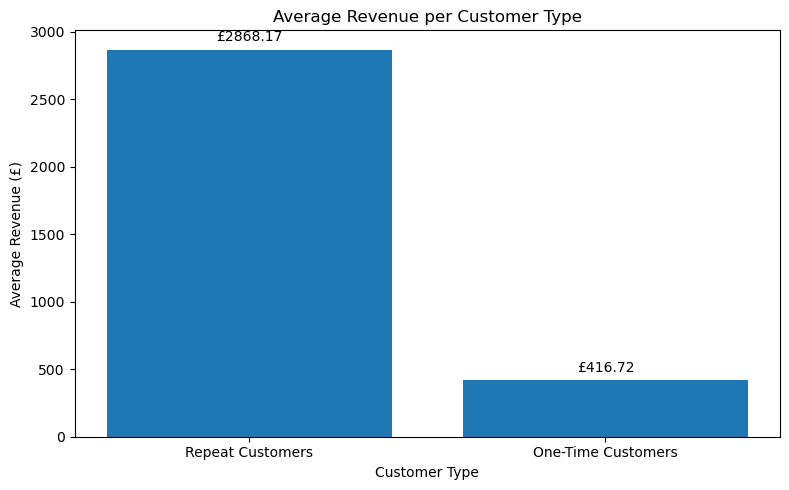

In [56]:
import matplotlib.pyplot as plt

customer_types = ["Repeat Customers", "One-Time Customers"]
average_revenue = [
    repeat_avg_revenue,
    one_time_avg_revenue
]

plt.figure(figsize=(8, 5))

bars = plt.bar(customer_types, average_revenue)

plt.title("Average Revenue per Customer Type")
plt.ylabel("Average Revenue (£)")
plt.xlabel("Customer Type")

plt.bar_label(bars, fmt="£%.2f", padding=4)

plt.tight_layout()
plt.show()

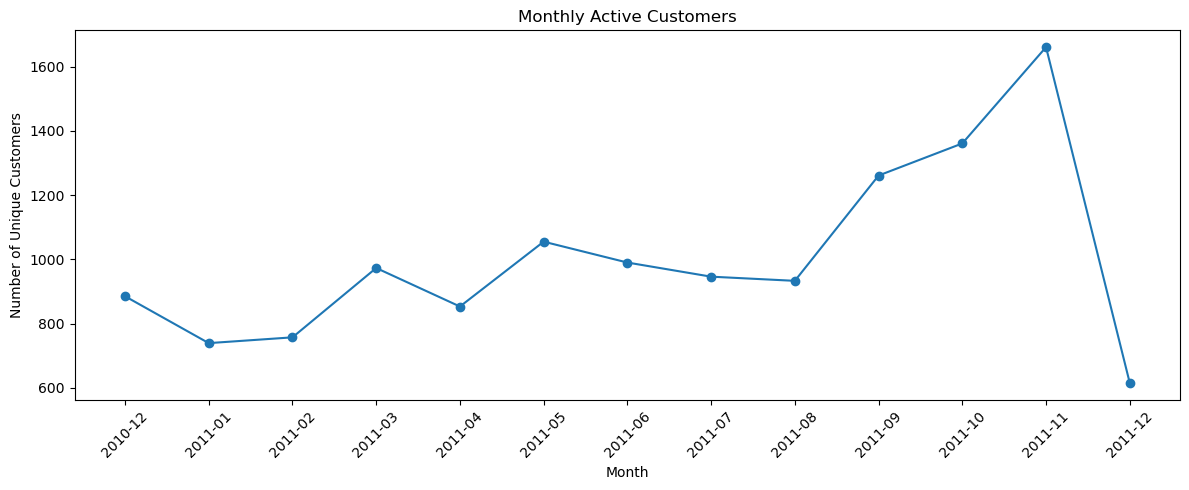

In [57]:
monthly_customers = (
    merchandise_df.groupby("YearMonth")["CustomerID"]
    .nunique()
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_customers.index.astype(str),
    monthly_customers.values,
    marker="o"
)

plt.title("Monthly Active Customers")
plt.xlabel("Month")
plt.ylabel("Number of Unique Customers")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

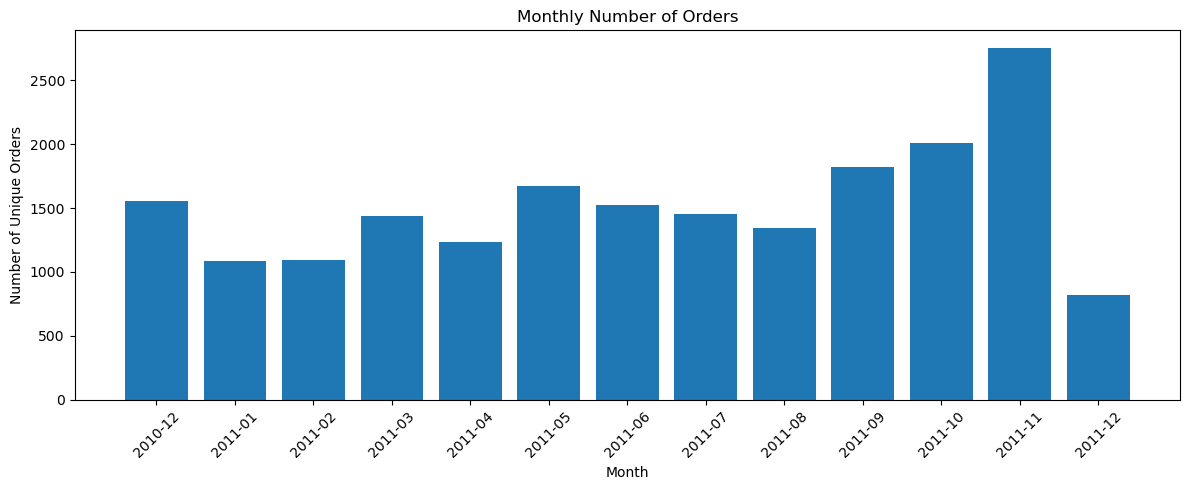

In [58]:
monthly_orders = (
    merchandise_df.groupby("YearMonth")["InvoiceNo"]
    .nunique()
)

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_orders.index.astype(str),
    monthly_orders.values
)

plt.title("Monthly Number of Orders")
plt.xlabel("Month")
plt.ylabel("Number of Unique Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

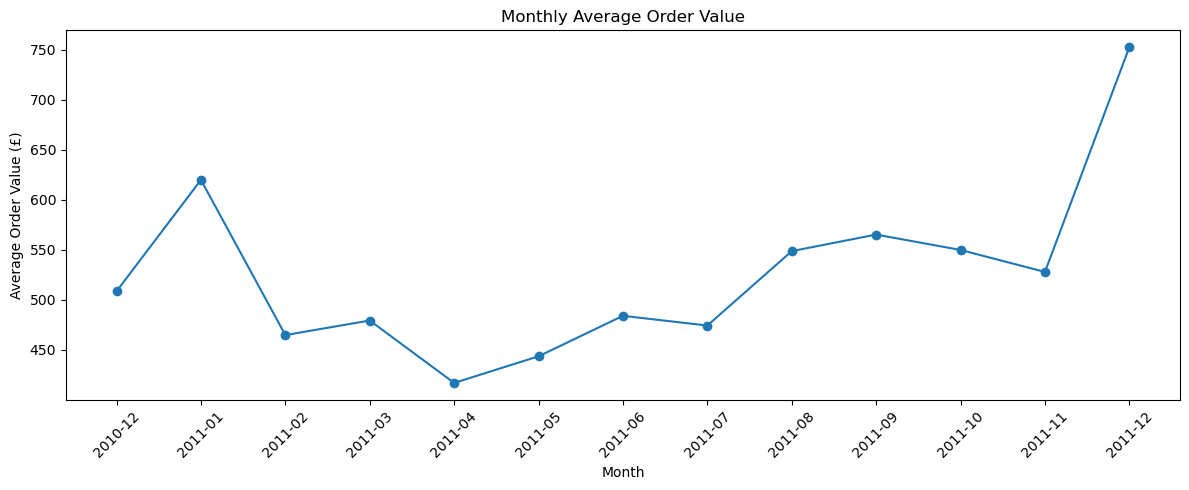

In [59]:
monthly_aov = (
    merchandise_df.groupby("YearMonth")
    .agg(
        Revenue=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
)

monthly_aov["AverageOrderValue"] = (
    monthly_aov["Revenue"] / monthly_aov["Orders"]
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_aov.index.astype(str),
    monthly_aov["AverageOrderValue"],
    marker="o"
)

plt.title("Monthly Average Order Value")
plt.xlabel("Month")
plt.ylabel("Average Order Value (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [60]:
best_revenue_month = monthly_aov["Revenue"].idxmax()
most_orders_month = monthly_aov["Orders"].idxmax()
highest_aov_month = monthly_aov["AverageOrderValue"].idxmax()

print("Highest revenue month:", best_revenue_month)
print("Highest order volume month:", most_orders_month)
print("Highest average order value month:", highest_aov_month)

print("\nHighest monthly revenue: £",
      round(monthly_aov["Revenue"].max(), 2))

print("Highest monthly orders:",
      monthly_aov["Orders"].max())

print("Highest monthly AOV: £",
      round(monthly_aov["AverageOrderValue"].max(), 2))

Highest revenue month: 2011-11
Highest order volume month: 2011-11
Highest average order value month: 2011-12

Highest monthly revenue: £ 1453295.98
Highest monthly orders: 2753
Highest monthly AOV: £ 752.4


In [61]:
import pandas as pd
import sqlite3

# Connect to an SQLite database
conn = sqlite3.connect("../data/sales_analysis.db")

# Check the data we're going to load
print("Rows:", len(merchandise_df))
print("Columns:", merchandise_df.columns.tolist())

Rows: 522729
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'YearMonth']


In [63]:
# Create a copy so the original DataFrame remains unchanged
sql_df = merchandise_df.copy()

# Convert YearMonth from Period to string
sql_df["YearMonth"] = sql_df["YearMonth"].astype(str)

# Load the data into SQLite
sql_df.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

print("Dataset successfully loaded into SQLite!")

# Verify the number of rows
result = pd.read_sql_query(
    "SELECT COUNT(*) AS total_rows FROM sales",
    conn
)

print(result)

Dataset successfully loaded into SQLite!
   total_rows
0      522729


In [65]:
query = """
SELECT
    Country,
    ROUND(SUM(Revenue), 2) AS Total_Revenue
FROM sales
GROUP BY Country
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

top_countries = pd.read_sql_query(query, conn)

display(top_countries)

,Country,Total_Revenue
0,United Kingdom,8751655.68
1,Netherlands,283889.34
2,EIRE,276090.86
3,Germany,205381.15
4,France,184679.00
5,Australia,138103.81
6,Spain,55706.56
7,Switzerland,53065.60
8,Japan,37416.37
9,Belgium,36927.34


In [66]:
query = """
SELECT
    Description,
    ROUND(SUM(Revenue), 2) AS Total_Revenue
FROM sales
WHERE Description IS NOT NULL
GROUP BY Description
ORDER BY Total_Revenue DESC
LIMIT 10;
"""

top_products = pd.read_sql_query(query, conn)

display(top_products)

,Description,Total_Revenue
0,REGENCY CAKESTAND 3 TIER,174156.54
1,"PAPER CRAFT , LITTLE BIRDIE",168469.60
2,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
3,PARTY BUNTING,99445.23
4,JUMBO BAG RED RETROSPOT,94159.81
5,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
6,RABBIT NIGHT LIGHT,66870.03
7,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59
8,ASSORTED COLOUR BIRD ORNAMENT,58927.62
9,CHILLI LIGHTS,54096.36


In [67]:
query = """
SELECT
    YearMonth,
    ROUND(SUM(Revenue), 2) AS Monthly_Revenue,
    COUNT(DISTINCT InvoiceNo) AS Total_Orders
FROM sales
GROUP BY YearMonth
ORDER BY YearMonth;
"""

monthly_sales_sql = pd.read_sql_query(query, conn)

display(monthly_sales_sql)

,YearMonth,Monthly_Revenue,Total_Orders
0,2010-12,789871.28,1553
1,2011-01,670654.46,1082
2,2011-02,508081.54,1093
3,2011-03,690811.60,1441
4,2011-04,515914.66,1237
5,2011-05,740487.33,1669
6,2011-06,738233.99,1525
7,2011-07,688802.67,1452
8,2011-08,735770.22,1341
9,2011-09,1029275.38,1821


In [68]:
query = """
SELECT
    YearMonth,
    ROUND(SUM(Revenue), 2) AS Monthly_Revenue,
    COUNT(DISTINCT InvoiceNo) AS Total_Orders,
    ROUND(
        SUM(Revenue) * 1.0 /
        COUNT(DISTINCT InvoiceNo), 2
    ) AS Average_Order_Value
FROM sales
GROUP BY YearMonth
ORDER BY YearMonth;
"""

monthly_aov_sql = pd.read_sql_query(query, conn)

display(monthly_aov_sql)

,YearMonth,Monthly_Revenue,Total_Orders,Average_Order_Value
0,2010-12,789871.28,1553,508.61
1,2011-01,670654.46,1082,619.83
2,2011-02,508081.54,1093,464.85
3,2011-03,690811.60,1441,479.40
4,2011-04,515914.66,1237,417.07
5,2011-05,740487.33,1669,443.67
6,2011-06,738233.99,1525,484.09
7,2011-07,688802.67,1452,474.38
8,2011-08,735770.22,1341,548.67
9,2011-09,1029275.38,1821,565.23


In [69]:
from pathlib import Path

# Create an output folder for reports
output_dir = Path("../reports")
output_dir.mkdir(parents=True, exist_ok=True)

# Export SQL analysis results
top_countries.to_csv(
    output_dir / "top_countries.csv",
    index=False
)

top_products.to_csv(
    output_dir / "top_products.csv",
    index=False
)

monthly_sales_sql.to_csv(
    output_dir / "monthly_sales.csv",
    index=False
)

monthly_aov_sql.to_csv(
    output_dir / "monthly_aov.csv",
    index=False
)

print("All four SQL reports exported successfully!")
print("Saved to:", output_dir.resolve())

All four SQL reports exported successfully!
Saved to: /Users/raghawmishra/Documents/sales_business_analytics/reports


In [70]:
# Export the full merchandise dataset for Power BI
powerbi_file = output_dir / "sales_dashboard_data.csv"

sql_df.to_csv(
    powerbi_file,
    index=False
)

print("Power BI dataset exported successfully!")
print("File location:", powerbi_file.resolve())
print("Rows exported:", len(sql_df))

Power BI dataset exported successfully!
File location: /Users/raghawmishra/Documents/sales_business_analytics/reports/sales_dashboard_data.csv
Rows exported: 522729
